# Ubicar un puntaje publicado en la distribución de su propio protocolo: el 0,943 del ensamble de apilamiento

**Pregunta:** ¿Dónde queda un puntaje publicado con partición aleatoria dentro de su propio protocolo?

**Nivel 3: Estado del arte** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts, 04-benchmark-protocol/02-scores-the-null-and-the-interval · Tiempo de lectura: unos 35 minutos

## Objetivos

El predictor publicado más reciente en este corpus es un ensamble de apilamiento reportado con una varianza explicada de 0,943, a partir de una sola partición aleatoria 80/20. Un solo número no puede decir si esa partición fue típica. Este notebook reajusta el método publicado en el motor, repite su protocolo 100 veces y pregunta dónde cae 0,943 entre los resultados que da el propio protocolo.

Al terminar habrá:

- reajustado el ensamble de apilamiento y la regresión de vectores soporte de núcleo polinómico, los dos predictores cuyos parámetros declara la fuente, en 100 particiones aleatorias y ubicado cada cifra publicada entre sus propios resultados;
- repetido las particiones tras colapsar los vectores de entradas duplicados, para probar si los duplicados explican la brecha;
- dejado fuera una campaña completa para los mismos predictores, y puesto al lado la ecuación clásica del producto para ver si el protocolo cambia su puntaje.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los puntajes publicados 0,943 (apilamiento) y 0,578 (vectores soporte, polinómico) | Sui et al. 2025, https://doi.org/10.3390/app15031254 | hechos numéricos reutilizados con cita (acceso abierto, CC BY) | `bf.PUBLISHED_RANDOM_SPLIT_R2` dentro del paquete `blastfrag` |

No se lee nada de un archivo horneado: toda distribución que sigue se recalcula reajustando los predictores sobre el corpus.

## Método

Para un predictor y un protocolo, el motor produce un puntaje por partición. La cifra publicada se ubica en esa distribución: la proporción de particiones que caen bajo ella dice si es un resultado típico del protocolo o uno favorable. Solo se ubican los dos predictores cuyos parámetros declara la fuente sin ambigüedad. La fuente imprime dos conjuntos de parámetros para su bosque aleatorio y su gradient boosting y no dice cuál produjo el 0,797 y el 0,758 que reporta, así que esos dos se dejan fuera y no se comparan con una elección arbitraria.

Las particiones son `repeated_random_splits` (100 particiones, semillas 0 a 99) y `repeated_deduplicated_splits` del motor; cada pliegue reajusta el predictor desde cero, y el puntaje es `r2_identity`, la varianza explicada respecto de la línea identidad. Qué mirar: si 0,943 es típico de su protocolo, si los duplicados explican lo que no lo es, y qué hace dejar una campaña fuera.

### Paso 1: una partición, reajustada

Antes de las 100 particiones, la celda reajusta ambos predictores en la partición única de la semilla 0 y pone el resultado junto a la cifra publicada, para que la diferencia entre una partición y una distribución se vea de inmediato.

In [2]:
# Una partición con semilla, reajustada para los dos predictores cuyos parámetros declara la fuente
factories = bf.default_arms()
published = bf.PUBLISHED_RANDOM_SPLIT_R2
split = bf.random_split(train, seed=0)
rows = []
for name, figure in published.items():
    model = factories[name]().fit(split.train)
    seed_zero = bf.score(split.test, model.predict(split.test)).r2_identity
    rows.append((name, f"{figure:.3f}", f"{seed_zero:.4f}"))
print(f"{split.protocol} | seed {split.seed} | {len(split.train)} entrenamiento, {len(split.test)} prueba")
show_table(["predictor", "publicado, una partición", "semilla 0, reajustado aquí"], rows)

random-8020 | seed 0 | 78 entrenamiento, 19 prueba


predictor,"publicado, una partición","semilla 0, reajustado aquí"
stacking,0.943,0.6933
svr-poly,0.578,0.2211


En la partición de la semilla 0, con 78 tiros para entrenamiento y 19 para prueba, el ensamble de apilamiento reajustado puntúa 0,6933 donde el artículo reporta 0,943, y la regresión de vectores soporte puntúa 0,2211 donde el artículo reporta 0,578. Una partición del método publicado sobre las mismas filas no devuelve el número publicado, y las dos difieren mucho de las cifras. Eso solo no dice que el artículo esté equivocado: una sola partición de 19 tiros de prueba es ruidosa, y los parámetros del motor son los que declara la fuente. Dice que la pregunta siguiente es la distribución de las particiones, no el valor de una.

## Estado del arte

- **Sui, Zhou, Zhao, Yang y Zou 2025** (https://doi.org/10.3390/app15031254) ajustan un ensamble de apilamiento de un bosque aleatorio y gradient boosting bajo un metaaprendiz lineal sobre los 97 tiros y reportan una varianza explicada de 0,943 en una partición aleatoria 80/20. La base de investigación del SDD registra que los autores probaron validación cruzada y la quitaron, de modo que la partición única es toda la evidencia.
- **Amoako, Jha y Zhong 2022** (https://doi.org/10.3390/mining2020013) ajustan regresores de vectores soporte con dos núcleos sobre las mismas filas y llegan a la conclusión opuesta sobre el núcleo respecto del estudio de 2025.
- El remuestreo que ignora la dependencia de los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

La afirmación "un ensamble aprendido predice la fragmentación en 0,94" descansa entonces en una sola partición, sin dispersión y sin campaña fuera. Los pasos que siguen corren ese método publicado, mediante la implementación del motor, sobre las mismas filas y bajo los protocolos del producto.

### Paso 2: 100 particiones aleatorias

La celda ajusta cada predictor en las filas de entrenamiento de cada partición, puntúa las filas de prueba y reúne los 100 valores. Demora cerca de medio minuto porque el ensamble de apilamiento reajusta un bosque y un modelo potenciado cada vez. La tabla ubica la cifra publicada entre las particiones, y los histogramas la dibujan como una línea.

predictor,publicado,mediana,10 %,90 %,particiones bajo lo publicado
stacking,0.943,0.7033,0.529,0.835,100 de 100
svr-poly,0.578,0.3947,0.169,0.627,83 de 100


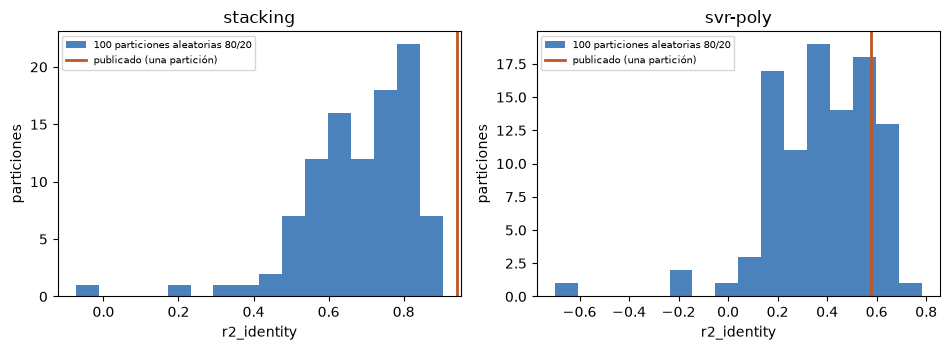

In [3]:
# Un puntaje por partición aleatoria 80/20, en 100 particiones, con la cifra publicada ubicada entre ellos
def draw_scores(name, splits):
    # Un valor de varianza explicada por partición, cada pliegue reajustado desde cero
    values = []
    for draw in splits:
        model = factories[name]().fit(draw.train)
        values.append(bf.score(draw.test, model.predict(draw.test)).r2_identity)
    return np.array(values)


random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
random_scores = {name: draw_scores(name, random_draws) for name in published}
rows = []
for name, figure in published.items():
    v = random_scores[name]
    low, high = np.quantile(v, [0.1, 0.9])
    below = int((v < figure).sum())
    rows.append((name, f"{figure:.3f}", f"{np.median(v):.4f}", f"{low:.3f}", f"{high:.3f}", f"{below} de {len(v)}"))
show_table(["predictor", "publicado", "mediana", "10 %", "90 %", "particiones bajo lo publicado"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, (name, figure) in zip(axes, published.items()):
    ax.hist(random_scores[name], bins=16, color="#2b6cb0", alpha=0.85, label="100 particiones aleatorias 80/20")
    ax.axvline(figure, color="#c05621", lw=2, label="publicado (una partición)")
    ax.set_xlabel("r2_identity")
    ax.set_ylabel("particiones")
    ax.set_title(name)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Para el ensamble de apilamiento las 100 particiones aleatorias tienen una mediana de 0,7033 y van de 0,529 en el percentil 10 a 0,835 en el 90, y las 100 caen bajo el 0,943 publicado, que queda a la derecha de todo el histograma. La regresión de vectores soporte es distinta: su mediana es 0,3947, su rango del percentil 10 al 90 es de 0,169 a 0,627, y 83 de las 100 particiones caen bajo el 0,578 publicado, de modo que esa cifra es una partición favorable pero posible. El primer panel dice entonces que la cifra del apilamiento no es un resultado típico de su propio protocolo, y el segundo dice que la otra cifra publicada sí lo es. La figura no dice por qué: una partición afortunada, un conjunto de parámetros distinto o una preparación de variables distinta en la fuente producirían lo mismo.

### Paso 3: ¿explican los duplicados la brecha?

Una partición aleatoria pone gemelos de un tiro de prueba en entrenamiento, como contó el primer notebook de este tema. Si los duplicados explicaran la brecha entre una cifra publicada y una partición típica, colapsarlos primero bajaría los puntajes. La celda repite ambos predictores en 100 particiones deduplicadas y compara las medianas; los diagramas de caja ponen los dos protocolos lado a lado con la línea publicada.

predictor,mediana aleatoria,mediana deduplicada,diferencia,peor partición aleatoria,peor partición deduplicada
stacking,0.7033,0.6995,-0.0038,-0.07,-0.11
svr-poly,0.3947,0.3959,+0.0012,-0.70,-10.88


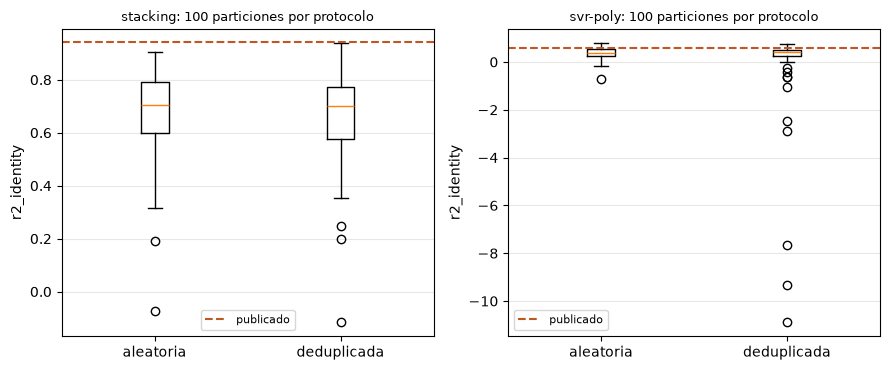

In [4]:
# Los mismos dos predictores en 100 particiones deduplicadas, frente a las aleatorias
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
dedup_scores = {name: draw_scores(name, dedup_draws) for name in published}
rows = []
for name in published:
    random_median, dedup_median = np.median(random_scores[name]), np.median(dedup_scores[name])
    lowest = (random_scores[name].min(), dedup_scores[name].min())
    rows.append((name, f"{random_median:.4f}", f"{dedup_median:.4f}", f"{dedup_median - random_median:+.4f}",
                 f"{lowest[0]:.2f}", f"{lowest[1]:.2f}"))
show_table(["predictor", "mediana aleatoria", "mediana deduplicada",
            "diferencia", "peor partición aleatoria", "peor partición deduplicada"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8), sharey=False)
for ax, (name, figure) in zip(axes, published.items()):
    ax.boxplot([random_scores[name], dedup_scores[name]], tick_labels=["aleatoria", "deduplicada"])
    ax.axhline(figure, color="#c05621", lw=1.5, ls="--", label="publicado")
    ax.set_ylabel("r2_identity")
    ax.set_title(f"{name}: 100 particiones por protocolo", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

Colapsar los duplicados apenas mueve las medianas: el ensamble de apilamiento pasa de 0,7033 a 0,6995 y la regresión de vectores soporte de 0,3947 a 0,3959. Las cajas de los dos protocolos se superponen casi por completo, de modo que los gemelos del primer notebook no explican por qué el 0,943 publicado queda sobre todas las particiones. Las peores particiones difieren más: la peor del apilamiento es -0,07 al azar y -0,11 deduplicada, y la de la regresión de vectores soporte cae de -0,70 a -10,88, un puñado de particiones deduplicadas en las que un núcleo polinómico extrapola mal. La figura muestra que los duplicados no son la causa; no muestra cuál es la causa de los valores atípicos de la regresión de vectores soporte.

### Paso 4: la campaña fuera

La celda puntúa los mismos dos predictores con cada campaña fuera por turno, agrupando las predicciones fuera de pliegue, y suma dos predictores que no aprenden de los tamaños de las filas de entrenamiento: la ecuación clásica del producto, `kuznetsov`, y el nulo. Para cada uno, la diferencia entre la mediana aleatoria y el puntaje con la campaña fuera es la brecha de protocolo.

In [5]:
# Una campaña fuera para los mismos predictores, junto al predictor clásico del producto y el nulo
compared = [*published, "kuznetsov", "null"]
held_out = {}
for name in compared:
    tested, predicted = [], []
    for fold in bf.leave_one_site_out(train):
        model = factories[name]().fit(fold.train)
        tested += list(fold.test)
        predicted += model.predict(fold.test)
    held_out[name] = bf.score(tested, predicted).r2_identity
for name in ("kuznetsov", "null"):
    random_scores[name] = draw_scores(name, random_draws)
rows = []
for name in compared:
    median = np.median(random_scores[name])
    low, high = np.quantile(random_scores[name], [0.1, 0.9])
    gap = median - held_out[name]
    rows.append((name, f"{median:.4f}", f"{low:.3f} a {high:.3f}", f"{held_out[name]:.4f}", f"{gap:.4f}"))
show_table(["predictor", "mediana aleatoria", "particiones aleatorias, 10 a 90 %",
            "campaña fuera", "brecha de protocolo"], rows)

predictor,mediana aleatoria,"particiones aleatorias, 10 a 90 %",campaña fuera,brecha de protocolo
stacking,0.7033,0.529 a 0.835,-0.0345,0.7379
svr-poly,0.3947,0.169 a 0.627,-4.5457,4.9404
kuznetsov,0.3026,-0.355 a 0.681,0.3112,-0.0086
null,-0.0362,-0.242 a -0.001,-0.2163,0.1800


Con la campaña fuera, el ensamble de apilamiento cae de una mediana aleatoria de 0,7033 a -0,0345, una brecha de protocolo de 0,7379, y la regresión de vectores soporte de 0,3947 a -4,5457, una brecha de 4,9404. Los dos predictores que no aprenden tamaños de las filas de entrenamiento se comportan distinto: la ecuación clásica puntúa 0,3026 al azar y 0,3112 con la campaña fuera, una brecha de -0,0086, de modo que el protocolo no le cuesta nada, y el nulo pasa de -0,0362 a -0,2163, una brecha de 0,1800 que viene del movimiento de la media de entrenamiento. La pérdida es entonces una propiedad de aprender de campañas, no de que las campañas fuera sean más difíciles. La tabla no dice que la ecuación clásica sea mejor: sus factores de roca se derivaron por campaña desde predicciones publicadas, de modo que su puntaje con la campaña fuera no es ciego.

### Paso 5: una imagen de tres protocolos

La última celda pone todas las comparaciones en un eje: para cada predictor, el rango de sus particiones aleatorias entre los percentiles 10 y 90, su puntaje con la campaña fuera y, para los dos publicados, la cifra publicada.

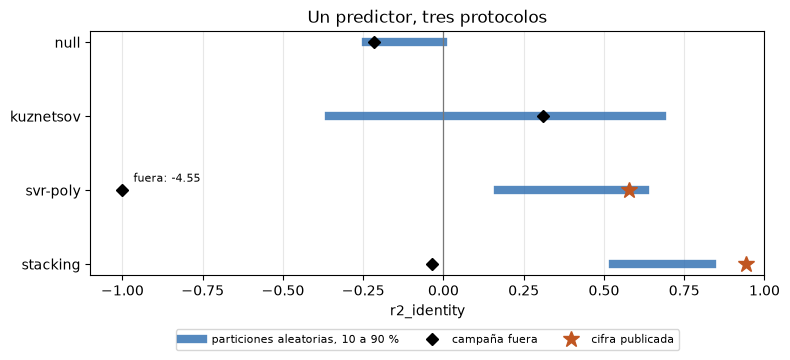

In [6]:
# Cada predictor en tres protocolos: dispersión aleatoria, puntaje con campaña fuera y cifra publicada
edge = -1.0
fig, ax = plt.subplots(figsize=(8.0, 3.8))
for row, name in enumerate(compared):
    low, high = np.quantile(random_scores[name], [0.1, 0.9])
    first = row == 0
    ax.plot([low, high], [row, row], lw=6, color="#2b6cb0", alpha=0.8,
            label="particiones aleatorias, 10 a 90 %" if first else None)
    ax.plot([max(held_out[name], edge)], [row], "D", color="black",
            label="campaña fuera" if first else None)
    if held_out[name] < edge:
        note = f"fuera: {held_out[name]:.2f}"
        ax.annotate(note, (edge, row), xytext=(8, 6), textcoords="offset points", fontsize=8)
    if name in published:
        ax.plot([published[name]], [row], "*", color="#c05621", ms=12,
                label="cifra publicada" if name == "stacking" else None)
ax.axvline(0, color="#777", lw=0.9)
ax.set_xlim(edge - 0.1, 1.0)
ax.set_yticks(range(len(compared)), compared)
ax.set_xlabel("r2_identity")
ax.set_title("Un predictor, tres protocolos")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

La imagen pone los tres protocolos en un eje. Las particiones aleatorias del ensamble de apilamiento ocupan de 0,529 a 0,835 y su cifra publicada queda más allá, en 0,943, mientras su puntaje con la campaña fuera es un rombo negro justo bajo cero; el 0,578 publicado de la regresión de vectores soporte cae dentro de su rango de 0,169 a 0,627 pero su puntaje con la campaña fuera, -4,5457, queda muy lejos del borde izquierdo del gráfico. El puntaje con la campaña fuera de la ecuación clásica queda dentro de su propia banda ancha, de -0,355 a 0,681, y la banda del nulo está en torno a cero con su puntaje con la campaña fuera en el extremo izquierdo. Lo que la figura muestra es el orden de las afirmaciones: una cifra publicada, un rango de resultados del mismo protocolo y la respuesta a la pregunta del profesional, que es otro lugar del eje. No ordena los predictores para una mina nueva.

## Resultados

**Respuesta:** el 0,943 publicado queda sobre cada una de las 100 particiones de su propio protocolo, cuya mediana es 0,7033 y cuyo rango del percentil 10 al 90 es de 0,529 a 0,835, así que es un resultado favorable y no la expectativa de una partición aleatoria 80/20. La otra cifra publicada, 0,578 para la regresión de núcleo polinómico, cae dentro de su rango (mediana 0,3947, 83 de 100 particiones bajo ella). Los duplicados no explican la brecha del apilamiento: colapsarlos mueve la mediana de 0,7033 a 0,6995. La campaña sí, porque con cada campaña fuera el mismo ensamble puntúa -0,0345, una brecha de protocolo de 0,7379, y la regresión de núcleo polinómico -4,5457. La ecuación clásica del producto puntúa 0,3026 al azar y 0,3112 con la campaña fuera, de modo que no paga por el protocolo.

**Lo que esto no muestra.** No muestra que el 0,943 esté equivocado como afirmación sobre la partición de los autores; muestra que una partición es una extracción de una distribución y que la distribución responde una pregunta distinta de la del profesional. Los otros dos predictores de la fuente se dejan fuera porque no dice cuál de dos conjuntos de parámetros produjo sus cifras. Los puntajes con la campaña fuera descansan en diez campañas, y las constantes de la ecuación clásica no son ciegas a la campaña, lo que el notebook siguiente sopesa con intervalos.

## Resumen

- Un puntaje publicado es una partición: el motor lo ubica en 100 particiones de su propio protocolo, y 0,943 queda sobre todas ellas para el ensamble de apilamiento, mientras 0,578 queda dentro del rango de la regresión de núcleo polinómico.
- Los vectores de entradas duplicados no explican la brecha (un cambio de -0,0038 en la mediana); dejar la campaña fuera sí.
- La brecha es -0,0086 para la ecuación clásica y 0,7379 para el ensamble de apilamiento, de modo que el costo del protocolo pertenece al aprendizaje desde campañas.
- Siguiente: el notebook 04 corre todo predictor bajo el protocolo y aplica el criterio predeclarado (nivel 4).

## Referencias

- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el ensamble de apilamiento, 0,943, 0,578)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores soporte sobre las mismas filas)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (dependencia en la validación cruzada)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/